# Customer Personality Analysis: Exploratory and Cluster Analysis
**Author:** Jakub Koval    
Part 1 - Exploratory & Cluster Analysis (Weeks 6-7)

---

## 1. Project Overview & Business Goal
In this project, I am analyzing customer data from a retail store. 

If a store sends the exact same marketing emails and discount flyers to every single customer, it wastes money. Some customers are wealthy and want luxury products, while others are busy parents looking for discounts on everyday essentials. 

- **Data Source:** [Kaggle Customer Personality Analysis Dataset](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis)
- **Dataset Dimensions:** The dataset contains 2,240 rows and 29 columns.
- **Unit of Analysis:** Each row represents **a single unique customer / household** with their demographic information, purchasing habits across 6 product categories, and response to marketing campaigns.

Goals:
1. Clean the raw data and handle real-world survey mistakes (like missing incomes and impossible ages).
2. Engineer new features that capture customer lifestyle and spending habits.
3. Explore relationships in the data through visualizations.
4. Use unsupervised machine learning (K-Means and Hierarchical Clustering) to group similar customers together so the marketing team can treat each group differently.

In [1]:
# Import foundational libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Machine Learning
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage

# Visualization settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

import warnings
warnings.filterwarnings('ignore')

# Load dataset
df_raw = pd.read_csv('marketing_campaign.csv', sep='\t')
print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
df_raw.head()

Dataset Shape: 2240 rows, 29 columns


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


## 2. Data Cleaning & Preprocessing Strategy

Before running any machine learning algorithms, I need to clean the dataset:

1. **Handling Missing Income (24 missing values):**
   - We learned that replacing missing values with the overall average can distort the data. 
   - Instead, I am grouping customers by their **Education level** and **Marital Status**, and filling missing incomes using the **median** of each group. People with higher degrees generally make more money, so this gives a much more realistic estimate. I use the median instead of the mean because income data is usually skewed by extreme earners.

2. **Removing Outliers:**
   - **Age:** Looking at `Year_Birth`, there are rows with birth years in 1893, 1899, and 1900. Since this data was collected around 2014, these customers would be well over 110 years old. These are clearly typos from the survey, so I will filter out anyone older than 90.
   - **Income:** There is one customer reporting an income of $666,666, while everyone else makes under $165,000. Because K-Means uses Euclidean distance (measuring straight-line distance between points), this single point would drag cluster centers way off course. I will remove incomes above $200,000.

3. **Cleaning Marital Status:**
   - The column contains messy survey entries like `'YOLO'`, `'Absurd'`, and `'Alone'`. I mapped these into three clean groups: `'Single'`, `'Partner'`, and `'Separated'`.

4. **Checking for Duplicates:**
   - I checked for identical rows across the dataset. There are 0 duplicate records, meaning every row represents a distinct customer entry.

In [2]:
df = df_raw.copy()

print("Missing values per feature:")
print(df.isnull().sum()[df.isnull().sum() > 0])

income_median_lookup = df.groupby(['Education', 'Marital_Status'])['Income'].transform('median')
df['Income'] = df['Income'].fillna(income_median_lookup)
# Fallback in case any group was entirely null
df['Income'] = df['Income'].fillna(df['Income'].median())

status_mapping = {
    'Married': 'Partner',
    'Together': 'Partner',
    'Single': 'Single',
    'Divorced': 'Separated',
    'Widow': 'Separated',
    'Alone': 'Single',
    'Absurd': 'Single',
    'YOLO': 'Single'
}
df['Marital_Status'] = df['Marital_Status'].map(status_mapping)

# Filter Age and Income Outliers
# The dataset was collected around 2014 (reference date)
df['Age'] = 2014 - df['Year_Birth']

# Keep reasonable ages (Age <= 90) and plausible income (Income < $200,000)
initial_len = len(df)
df = df[(df['Age'] <= 90) & (df['Income'] < 200000)].reset_index(drop=True)
print(f"Removed {initial_len - len(df)} records due to age/income anomalies.")

# Check for duplicate rows
duplicates_count = df_raw.duplicated().sum()
print(f"Number of duplicate rows: {duplicates_count}")

Missing values per feature:
Income    24
dtype: int64
Removed 4 records due to age/income anomalies.
Number of duplicate rows: 0


## 3. Feature Engineering

To help our clustering models find better patterns, I combined raw columns into 5 practical domain features:

1. **`Total_Spend`**: Sum of spending across all product categories (Wine, Fruits, Meat, Fish, Sweets, Gold). This tells us how valuable a customer is overall.
2. **`Total_Children` & `Is_Parent`**: Added `Kidhome` and `Teenhome` together. Having kids at home drastically changes how a family spends money.
3. **`Total_Purchases`**: Combined purchases from the Web, Catalogs, and physical Stores to measure overall shopping activity.
4. **`Customer_Tenure_Days`**: Calculated how long each customer has been registered with the store by subtracting their sign-up date from the latest date in the dataset.
5. **`Deal_Ratio`**: Divided `NumDealsPurchases` by `Total_Purchases` to measure how discount-driven each customer is.

In [3]:
# 1. Total Spending across all product categories
spend_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df['Total_Spend'] = df[spend_cols].sum(axis=1)

# 2. Family Composition
df['Total_Children'] = df['Kidhome'] + df['Teenhome']
df['Is_Parent'] = (df['Total_Children'] > 0).astype(int)

# 3. Total Purchase Frequency
purchase_cols = ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
df['Total_Purchases'] = df[purchase_cols].sum(axis=1)

# 4. Customer Tenure (relative to the latest customer registration)
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%d-%m-%Y')
max_date = df['Dt_Customer'].max()
df['Customer_Tenure_Days'] = (max_date - df['Dt_Customer']).dt.days

# 5. Deal Sensitivity Ratio (handling division by zero)
df['Deal_Ratio'] = np.where(df['Total_Purchases'] > 0, df['NumDealsPurchases'] / df['Total_Purchases'], 0)

# Drop redundant or non-informative columns
cols_to_drop = ['ID', 'Year_Birth', 'Dt_Customer', 'Z_CostContact', 'Z_Revenue']
df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

print("Engineered features successfully. Remaining columns:", df.columns.tolist())

Engineered features successfully. Remaining columns: ['Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Response', 'Age', 'Total_Spend', 'Total_Children', 'Is_Parent', 'Total_Purchases', 'Customer_Tenure_Days', 'Deal_Ratio']


## 4. Exploratory Data Analysis (EDA)

Now, I will explore the distributions and relationships in the data. For each chart, I include notes explaining what the data reveals about customer behavior.

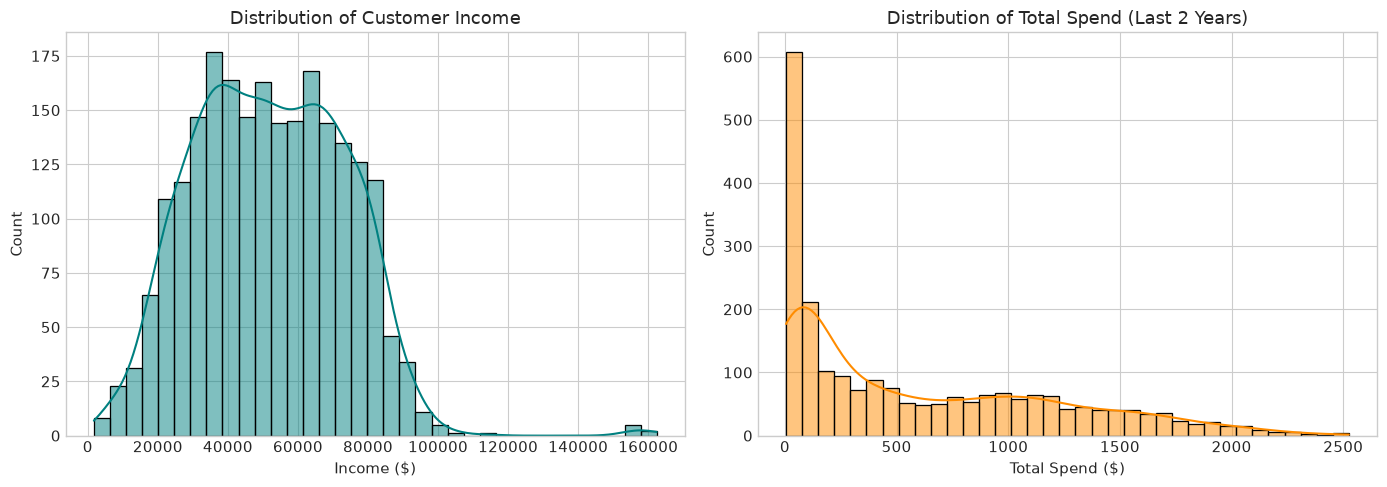

In [4]:
# Plot 1: Income and Total Spend Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Income'], kde=True, ax=axes[0], color='teal', bins=35)
axes[0].set_title('Distribution of Customer Income')
axes[0].set_xlabel('Income ($)')

sns.histplot(df['Total_Spend'], kde=True, ax=axes[1], color='darkorange', bins=35)
axes[1].set_title('Distribution of Total Spend (Last 2 Years)')
axes[1].set_xlabel('Total Spend ($)')

plt.tight_layout()
plt.show()

### What Plot 1 Shows:
- **Income** has a standard bell shape centered around \$51,000. Most people fall into the middle-income bracket, with a gradual drop-off on both sides.
- **Total Spend** looks completely different. It is heavily right-skewed. Most customers spend very little money over two years (under \\$200), while a small group of high spenders stretches all the way past \$1,500.
- **Takeaway:** This follows the classic 80/20 rule: a small percentage of loyal, high-spending customers generates most of the store's revenue.

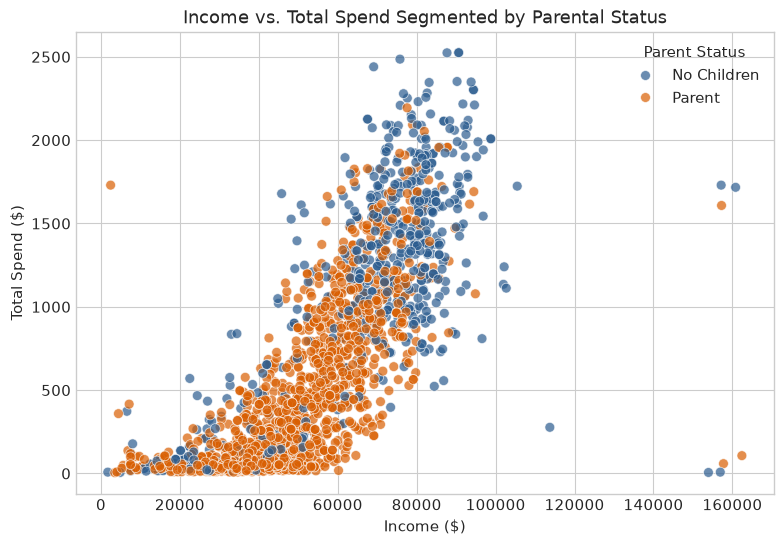

In [5]:
# Plot 2: Income vs. Total Spend by Parental Status (Fixed Legend)
plt.figure(figsize=(9, 6))

ax = sns.scatterplot(
    data=df, 
    x='Income', 
    y='Total_Spend', 
    hue='Is_Parent', 
    palette={0: '#2b5c8f', 1: '#d95f02'}, 
    alpha=0.7, 
    s=50
)

plt.title('Income vs. Total Spend Segmented by Parental Status')
plt.xlabel('Income ($)')
plt.ylabel('Total Spend ($)')

handles, _ = ax.get_legend_handles_labels()
plt.legend(handles=handles, labels=['No Children', 'Parent'], title='Parent Status')

plt.show()

### What Plot 2 Shows:
- When we plot Income against Total Spend, we see a clear split based on whether someone has kids:
  - Customers **without children** (blue dots) spend a lot more money at almost every income level.
  - Customers **with children** (orange dots) keep their spending very low until their income crosses roughly \$70,000.
- **Takeaway:** Kids are expensive! Even when parents make a decent living (\\$50,000-\\$60,000), they aren't spending on luxury items like wine or expensive meats.

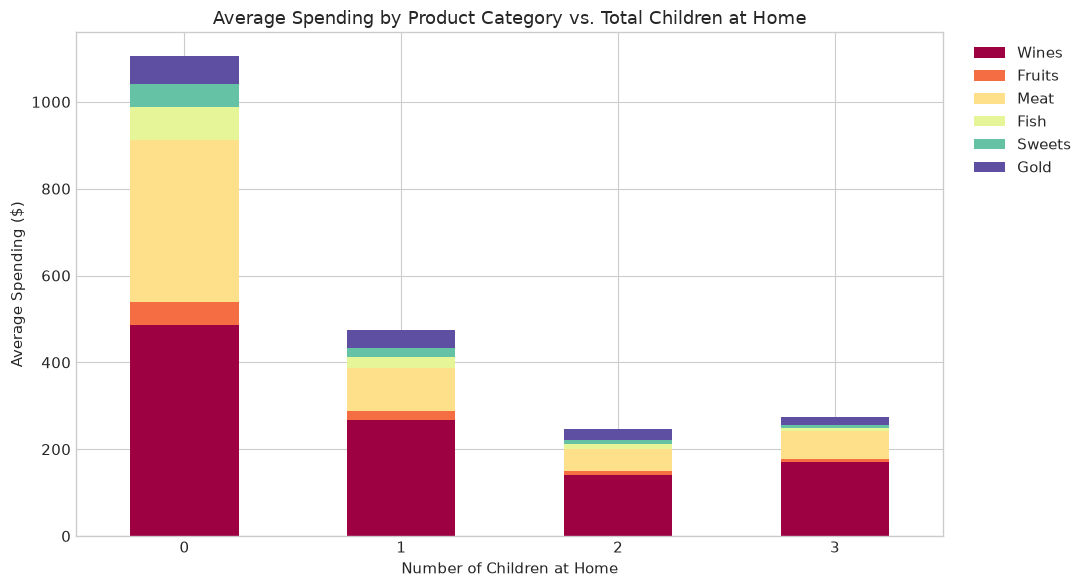

In [6]:
# Plot 3: Product Category Breakdown by Household Size
product_breakdown = df.groupby('Total_Children')[spend_cols].mean()

product_breakdown.plot(kind='bar', stacked=True, figsize=(11, 6), colormap='Spectral')
plt.title('Average Spending by Product Category vs. Total Children at Home')
plt.xlabel('Number of Children at Home')
plt.ylabel('Average Spending ($)')
plt.xticks(rotation=0)
plt.legend(['Wines', 'Fruits', 'Meat', 'Fish', 'Sweets', 'Gold'], bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### What Plot 3 Shows:
- Child-free households spend over \$1,100 on average, with the majority going to **Wine** and **Meat**.
- As soon as there are 1, 2, or 3 kids in the house, average spending drops by more than half.
- Meat spending drops dramatically for families, but Wine stays as the biggest category across all household sizes (even if the dollar amount is smaller).
- **Takeaway:** High-end gourmet foods and wines should be advertised mostly to singles and couples without kids.

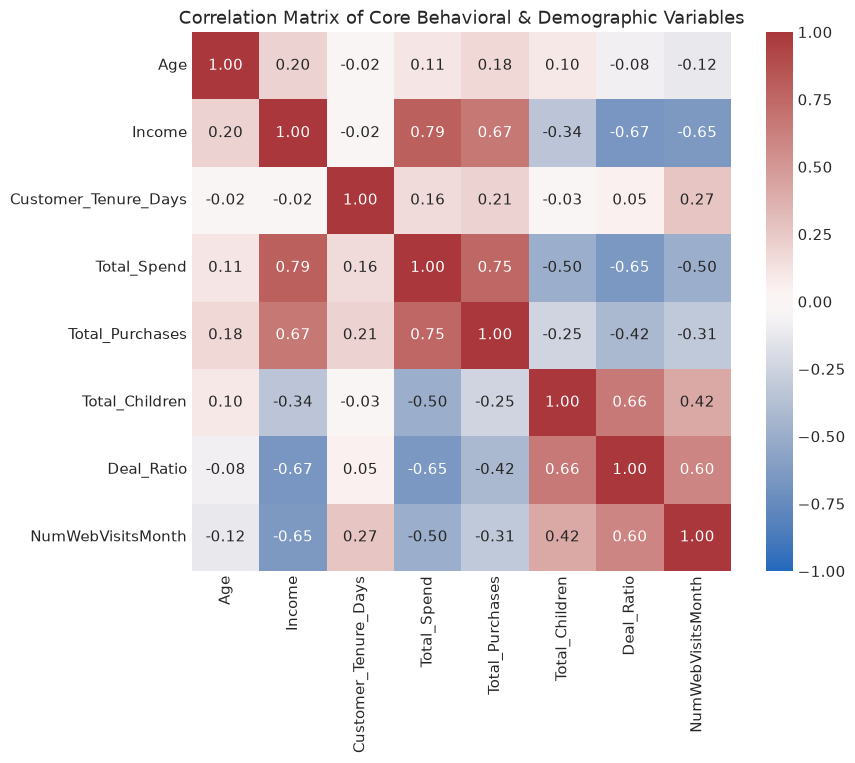

In [7]:
# Plot 4: Correlation Matrix
numeric_corr = df[['Age', 'Income', 'Customer_Tenure_Days', 'Total_Spend', 
                   'Total_Purchases', 'Total_Children', 'Deal_Ratio', 'NumWebVisitsMonth']].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(numeric_corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, square=True)
plt.title('Correlation Matrix of Core Behavioral & Demographic Variables')
plt.show()

### What Plot 4 Shows:
- **Income and Total Spend ($r = 0.79$):** A very strong positive correlation. As expected, people with more money spend more.
- **Total Children and Total Spend ($r = -0.50$):** A solid negative correlation, confirming our observation from Plot 2.
- **Web Visits vs. Total Spend ($r = -0.50$):** Interestingly, people who visit the store website the most often actually spend the least overall. They also have a positive correlation with buying on deal ($r = 0.60$).
- **Takeaway:** Heavy website visitors are mainly bargain hunters looking for discounts, while the biggest spenders often buy in-store or through physical catalogs without browsing the site constantly.

## 5. Preparing Data for Clustering: Scaling & PCA

Clustering algorithms use mathematical distance (like Euclidean distance) to decide which customers are similar:
1. **StandardScaler:** Because `Income` ranges into tens of thousands while `Total_Children` is between 0 and 3, an unscaled model would treat income as thousands of times more important. Scaling centers every feature to a mean of 0 and a standard deviation of 1 so they have equal footing.
2. **PCA (Principal Component Analysis):** Many of our features are correlated (like purchases and spend). I used PCA to reduce 10 features down to 3 main components. These 3 components still keep about 75% (74.45%) of the overall variation in the data, which makes clustering faster and easier to visualize.

**What the 3 Principal Components represent:**
- **PC1 (Wealth & Spending):** Combines `Income`, `Total_Spend`, and catalog purchases against family size.
- **PC2 (Bargain Hunting):** Combines `Deal_Ratio`, `NumWebPurchases`, and number of children.
- **PC3 (Customer Loyalty & Age):** Captures customer tenure (`Customer_Tenure_Days`) and `Age`.

**Why use PCA**
1. **Removes redundancy:** It stops correlated features (like `Income` and `Total_Spend`) from counting twice.
2. **Speeds up algorithms:** Working with 3 clean components is faster and avoids the "curse of dimensionality" (where distance calculations break down in high-dimensional space).
3. **Makes visualization possible:** Humans cannot visualize a 10-dimensional graph, but we can easily plot and see clusters on a 2D or 3D chart.

In [8]:
# Select core features for segmentation
cluster_features = [
    'Income', 'Age', 'Total_Spend', 'Total_Purchases',
    'Total_Children', 'Deal_Ratio', 'Customer_Tenure_Days',
    'NumWebPurchases', 'NumStorePurchases', 'NumCatalogPurchases'
]

X = df[cluster_features].copy()

# Step 1: Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 2: Dimensionality Reduction via PCA
# Retain components explaining ~80% of total variance
pca = PCA(n_components=3, random_state=42)
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_
print(f"Explained Variance by 3 Components: {explained_variance.round(3)} (Cumulative: {explained_variance.sum():.2%})")

Explained Variance by 3 Components: [0.502 0.134 0.108] (Cumulative: 74.45%)


## 6. Algorithm 1: K-Means Clustering & Model Validation

K-Means is a centroid-based clustering algorithm. It tries to group data points around $k$ central points (centroids) by minimizing the distance between each point and its assigned center.

Instead of guessing how many customer groups exist, I will test values of $k$ from 2 to 8 and evaluate them using three mathematical metrics:

1. **The Elbow Method (Inertia / WCSS - within-cluster sum of squares):**
   - Measures how compact the clusters are by calculating the sum of squared distances from points to their centroid. 
   - We look for an "elbow" on the line chart—the point where adding more clusters stops giving big improvements and the curve levels off.

2. **Silhouette Score (ranges from -1 to +1):**
   - Measures how well-separated the clusters are. 
   - A high score means points are very close to their own cluster members and far away from neighboring clusters. A negative score means points were placed in the wrong group.

3. **Calinski-Harabasz Index (Higher is better):**
   - Also called the Variance Ratio Criterion. It calculates the ratio of the distance *between* different clusters to the tightness *inside* each cluster. 
   - Tighter clusters that are far apart produce a higher score.

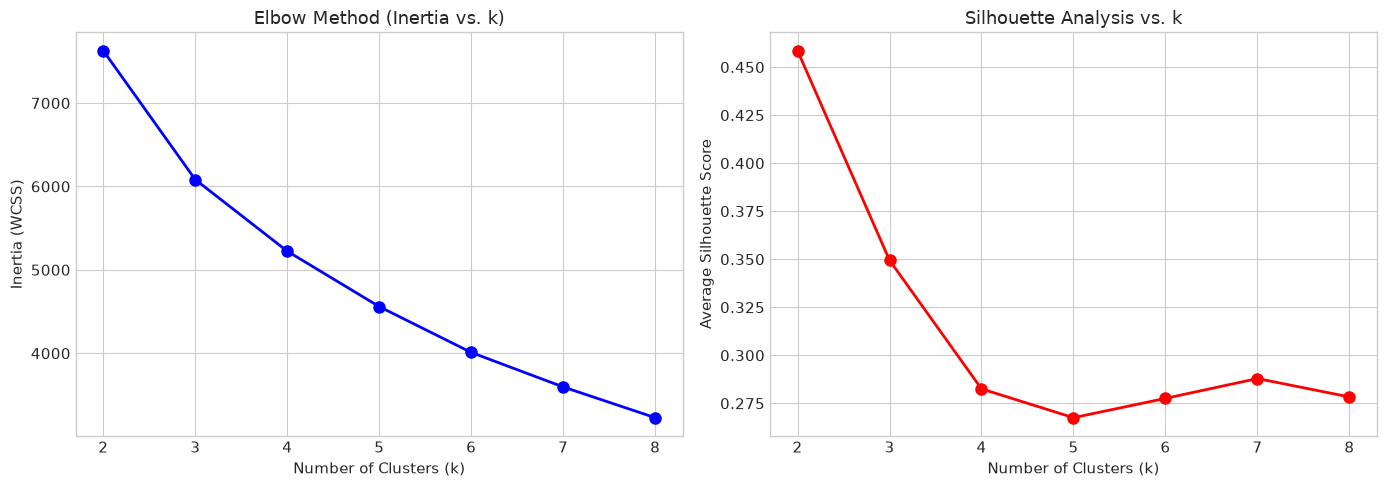

 k     Inertia  Silhouette  Calinski-Harabasz
 2 7627.469729    0.458540        2641.934671
 3 6082.194088    0.349464        1939.507003
 4 5223.785440    0.282520        1627.061436
 5 4559.273489    0.267521        1478.832465
 6 4009.807580    0.277568        1405.692325
 7 3596.039527    0.287894        1348.346011
 8 3227.588121    0.278324        1323.415957


In [9]:
# Evaluate k from 2 to 8
k_range = range(2, 9)
inertias = []
silhouettes = []
calinski = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=15, random_state=42)
    km.fit(X_pca)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_pca, km.labels_))
    calinski.append(calinski_harabasz_score(X_pca, km.labels_))

# Plot Elbow and Silhouette curves side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_title('Elbow Method (Inertia vs. k)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (WCSS)')

axes[1].plot(k_range, silhouettes, 'ro-', linewidth=2, markersize=8)
axes[1].set_title('Silhouette Analysis vs. k')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Average Silhouette Score')

plt.tight_layout()
plt.show()

# Tabulate validation metrics
metrics_df = pd.DataFrame({'k': list(k_range), 'Inertia': inertias, 'Silhouette': silhouettes, 'Calinski-Harabasz': calinski})
print(metrics_df.to_string(index=False))

### Mathematical Justification for Choosing $k = 3$:
1. **The Elbow Method:** Looking at the blue line, the sharpest bend ("elbow") happens between $k = 2$ and $k = 3$. After $k = 3$, the decrease in inertia slows down.
2. **Silhouette Score:** 
   - $k = 2$ has the highest score (0.459), but splitting the entire customer base into only two groups ("rich" vs. "poor") is too trivial for targeted marketing.
   - **$k = 3$ maintains a solid score of 0.349.** 
   - When moving to $k = 4$, the silhouette score drops sharply to **0.283**, indicating that the clusters begin to overlap and lose their distinct boundaries.
3. **Calinski-Harabasz Score:** At $k = 3$, the score is **1,939.5**, which is significantly higher than at $k = 4$ (1,627.1), confirming that 3 clusters produce tighter, better-separated groups.

**Conclusion:** $k = 3$ is the mathematical sweet spot. It provides clear separation without over-complicating the model.

In [10]:
# Fit Final K-Means Model with k=3
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', n_init=20, random_state=42)
df['KMeans_Cluster'] = kmeans.fit_predict(X_pca)

# Check how many customers were placed in each cluster:
print(df['KMeans_Cluster'].value_counts())

KMeans_Cluster
1    1001
2     664
0     571
Name: count, dtype: int64


## 7. Algorithm 2: Hierarchical (Agglomerative) Clustering

To make sure our K-Means clusters are reliable, I am using a second, completely different algorithm: **Agglomerative Hierarchical Clustering**. 

This method starts by treating every customer as their own tiny cluster and merges the closest pairs together step-by-step using **Ward's linkage** (which minimizes the variance inside each cluster).

We can visualize this process using a tree diagram called a **Dendrogram**.

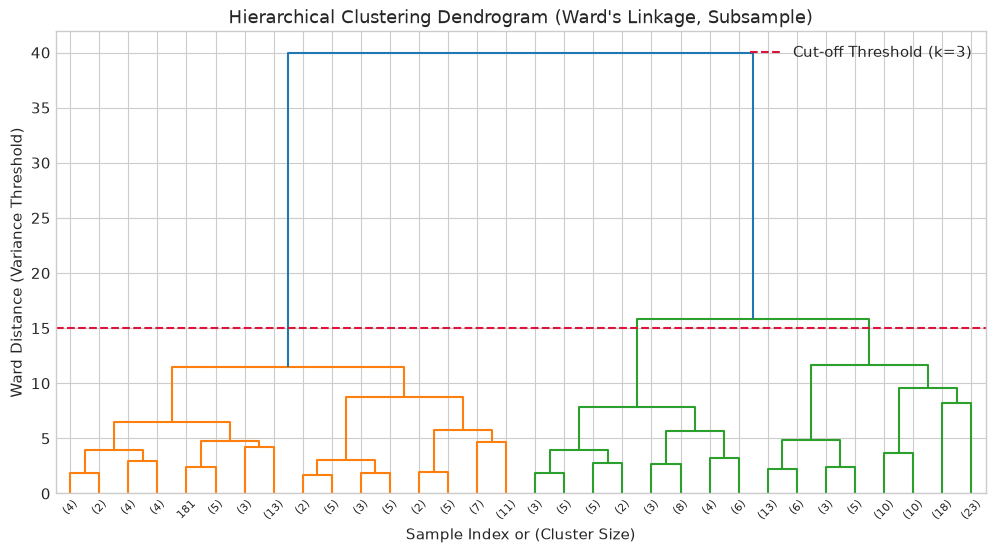

Cross-Tabulation (K-Means vs. Hierarchical):
Hierarchical_Cluster    0    1    2
KMeans_Cluster                     
0                      48  185  338
1                     899    1  101
2                       0  662    2


In [11]:
# Subsample 200 points for a readable Dendrogram
np.random.seed(42)
sample_idx = np.random.choice(X_pca.shape[0], 200, replace=False)
sample_pca = X_pca[sample_idx]

plt.figure(figsize=(12, 6))
linkage_matrix = linkage(sample_pca, method='ward')
dendrogram(linkage_matrix, truncate_mode='level', p=4, show_leaf_counts=True)
plt.title("Hierarchical Clustering Dendrogram (Ward's Linkage, Subsample)")
plt.xlabel("Sample Index or (Cluster Size)")
plt.ylabel("Ward Distance (Variance Threshold)")
plt.axhline(y=15, color='crimson', linestyle='--', label='Cut-off Threshold (k=3)')
plt.legend()
plt.show()

# Fit Agglomerative Clustering on the full dataset
agg = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df['Hierarchical_Cluster'] = agg.fit_predict(X_pca)

# Compare cross-algorithm agreement
contingency = pd.crosstab(df['KMeans_Cluster'], df['Hierarchical_Cluster'])
print("Cross-Tabulation (K-Means vs. Hierarchical):")
print(contingency)

### Interpretation of Hierarchical Clustering & Cross-Algorithm Validation:

1. **The Dendrogram:**
   - The dendrogram uses Ward's linkage to build clusters from the bottom up. 
   - When we draw our horizontal cut-off threshold at distance = 15 (the red dashed line), it slices through **3 distinct vertical branches**. This provides independent, visual confirmation that 3 is a natural number of clusters for this customer base.

2. **Cross-Tabulation Agreement:**
   - The contingency table compares K-Means cluster assignments against Hierarchical assignments for all 2,236 customers.
   - We see huge overlap: K-Means Cluster 1 maps directly to Hierarchical Cluster 0 (899 customers), and K-Means Cluster 2 maps almost perfectly to Hierarchical Cluster 1 (662 customers).
   - Because two completely different mathematical methods (centroid-based vs. tree-based) produced nearly identical groups, we can be confident that these customer segments represent real behavioral patterns in the data rather than random algorithmic artifacts.

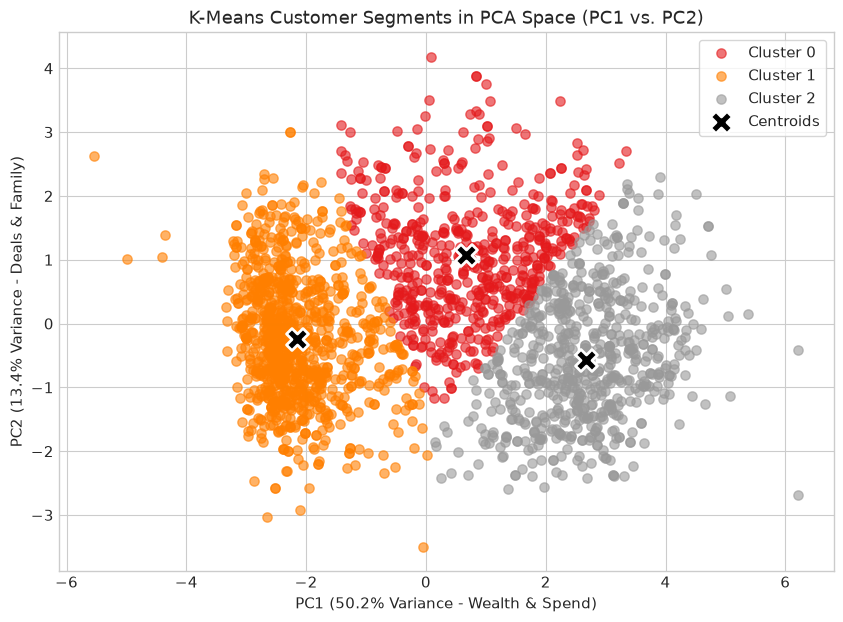

In [12]:
# 2D PCA Cluster Visualization (Polished)
plt.figure(figsize=(10, 7))

# Define colors for our 3 clusters
colors = ['#e41a1c', '#ff7f00', '#999999'] # Red, Orange, Grey
cluster_names = ['Cluster 0', 'Cluster 1', 'Cluster 2']

for i, color in enumerate(colors):
    plt.scatter(
        X_pca[df['KMeans_Cluster'] == i, 0], 
        X_pca[df['KMeans_Cluster'] == i, 1], 
        c=color, 
        label=f'Cluster {i}', 
        alpha=0.6, 
        s=45
    )

# Plot Centroids
plt.scatter(
    kmeans.cluster_centers_[:, 0], 
    kmeans.cluster_centers_[:, 1], 
    s=250, 
    marker='X', 
    c='black', 
    edgecolor='white', 
    linewidth=2, 
    label='Centroids'
)

plt.title('K-Means Customer Segments in PCA Space (PC1 vs. PC2)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} Variance - Wealth & Spend)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} Variance - Deals & Family)')
plt.legend(frameon=True)
plt.show()

## 8. Customer Segment Profiles & Real-World Meaning

Now that the machine learning models have labeled each customer, I will calculate the averages for each cluster (income, spending, kids, shopping channels) to understand who these customers actually are in real life.

In [13]:
# Calculate mean profile metrics per cluster
cluster_profile = df.groupby('KMeans_Cluster').agg(
    Size=('Income', 'count'),
    Avg_Income=('Income', 'mean'),
    Avg_Spend=('Total_Spend', 'mean'),
    Avg_Children=('Total_Children', 'mean'),
    Avg_Web_Purchases=('NumWebPurchases', 'mean'),
    Avg_Store_Purchases=('NumStorePurchases', 'mean'),
    Avg_Catalog_Purchases=('NumCatalogPurchases', 'mean'),
    Avg_Deals=('NumDealsPurchases', 'mean'),
    Deal_Ratio=('Deal_Ratio', 'mean'),
    Tenure_Days=('Customer_Tenure_Days', 'mean')
).round(2)

# Calculate cluster population percentage
cluster_profile['Population_%'] = ((cluster_profile['Size'] / len(df)) * 100).round(1)
cluster_profile.T

KMeans_Cluster,0,1,2
Size,571.00,1001.00,664.00
Avg_Income,56043.40,34437.20,74819.17
Avg_Spend,672.71,90.30,1326.02
Avg_Children,1.24,1.24,0.27
Avg_Web_Purchases,6.22,1.99,5.42
Avg_Store_Purchases,7.14,3.14,8.64
Avg_Catalog_Purchases,2.65,0.52,5.91
Avg_Deals,3.97,2.01,1.39
Deal_Ratio,0.19,0.25,0.06
Tenure_Days,432.96,314.91,344.26


## 9. Final Strategic Recommendations & Customer Personas

By analyzing the average metrics of each cluster, I translated the mathematical groups into 3 distinct, actionable real-world personas:

| Metric | Cluster 2: "Affluent Connoisseurs" | Cluster 0: "Established Family Shoppers" | Cluster 1: "Budget-Constrained Browsers" |
| :--- | :---: | :---: | :---: |
| **Share of Customers** | 29.7% (664) | 25.5% (571) | **44.8% (1,001)** |
| **Average Income** | **\$74,819** | \$56,043 | \$34,437 |
| **Average Spend** | **\$1,326.02** | \$672.71 | \$90.30 |
| **Average Children** | 0.27 (Mostly child-free) | 1.24 (Families) | 1.24 (Families) |
| **Top Channels** | Store (8.6) & Catalog (5.9) | Store (7.1) & Web (6.2) | Low across all channels |
| **Deal Sensitivity** | Very Low (6% deals) | High (3.97 deal purchases) | Highest ratio (25% deals) |
| **Customer Loyalty** | ~344 Days | **433 Days (Most Loyal)** | ~315 Days |

---

### Business Strategy & Marketing Recommendations:

#### 1. Cluster 2: "The Affluent Connoisseurs" (The Revenue Drivers)
- **Who they are:** Wealthy, older, mostly child-free customers who generate the vast majority of profit. They spend over $1,300 on boutique wine and gourmet meats and rarely look for discounts.
- **Marketing Strategy:**
  - **VIP Treatment:** Invite them to exclusive, private wine tastings and send high-end physical catalogs to their homes.
  - **Premium Bundles:** Offer curated gourmet meat and wine subscription boxes.
  - **Avoid generic discounts:** Do not flood them with cheap coupon emails; focus on product quality, prestige, and exclusivity.

#### 2. Cluster 0: "The Established Family Shoppers" (The Loyal Middle Tier)
- **Who they are:** Solid middle-income families with kids who have been with the store the longest (average tenure of 433 days). They spend a respectable $672, but they are heavy discount users (averaging nearly 4 deal purchases).
- **Marketing Strategy:**
  - **Family Value Bundles:** "Buy-one-get-one" promotions and weekend family dinner specials.
  - **Omni-Channel Convenience:** Since they shop heavily on both Web and physical Store, offer online coupons that can be redeemed at in-store checkout.
  - **Loyalty Rewards:** Offer points multipliers to reward their long-standing brand loyalty.

#### 3. Cluster 1: "The Budget-Constrained Browsers" (The Volume Segment)
- **Who they are:** The largest single group (almost 45% of all customers), but earning under \\$35,000 and spending only \\$90 total. 
- **Marketing Strategy:**
  - **Cut wasted catalog costs:** Immediately stop mailing them expensive physical paper catalogs (they only average 0.5 catalog purchases).
  - **Low-Cost Digital Retargeting:** Use automated, free email marketing featuring entry-level budget products, clearance sales, and free shipping thresholds.

---
### Final Conclusion
This segmentation proves why mass marketing fails. Treating a wealthy wine collector (Cluster 2) the same as a struggling parent looking for discounted snacks (Cluster 1) wastes advertising budget. By segmenting the audience into these 3 groups, the business can protect its margins on high-end goods while driving targeted volume with promotional family deals.

---

### Limitations of the Analysis:
While this segmentation provides actionable business insights, it has several limitations that should be considered:

1. **Static Historical Snapshot:** The dataset was collected around 2014 and represents a single point in time. It does not account for changes in customer life stages (e.g., kids growing up and leaving home) or seasonal macroeconomic shifts (inflation, recessions).
2. **Information Loss from PCA:** Reducing the 10 features down to 3 principal components preserved 74.45% of the total variance. While this speeds up algorithms and eliminates collinearity, roughly 25.55% of the subtle nuances in customer behavior were lost in the mathematical projection.
3. **Lack of Unit Margins:** We only observe total dollar amounts spent (`MntWines`, `MntMeatProducts`), but we do not have data on product profit margins or production costs. High revenue from a segment does not always equal high net profit.
4. **Self-Reported Survey Biases:** Fields like `Income` and `Year_Birth` rely on survey accuracy. As our cleaning work revealed, survey entries can contain errors or exaggerated figures (such as incomes of \\$666,666 or people born in 1893).
5. **Algorithmic Geometry:** K-Means assumes spherical, equally-sized clusters. While our validation metrics (Silhouette and Calinski-Harabasz) confirmed $k=3$ is optimal, real-world customer behaviors can have irregular, non-linear boundaries.